In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    f1_score,
    roc_auc_score
)


E0000 00:00:1782027576.635081     276 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782027576.643350     276 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782027576.664524     276 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782027576.664548     276 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782027576.664563     276 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782027576.664566     276 computation_placer.cc:177] computation placer already registered. Please check linka

In [4]:
# =========================
# PATHS
# =========================

train_path = "/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/train"
val_path = "/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/valid"
test_path = "/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake/test"



In [5]:
# =========================
# CONFIG
# =========================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

INITIAL_EPOCHS = 10
FINE_TUNE_EPOCHS = 10
TOTAL_EPOCHS = INITIAL_EPOCHS + FINE_TUNE_EPOCHS

In [6]:
# =========================
# DATA GENERATORS
# =========================

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

validation_generator = val_datagen.flow_from_directory(
    val_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)


Found 100000 images belonging to 2 classes.
Found 20000 images belonging to 2 classes.
Found 20000 images belonging to 2 classes.


In [7]:
# =========================
# BASE MODEL
# =========================

base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False


I0000 00:00:1782027631.962551     276 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1782027631.967950     276 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [8]:
# =========================
# CLASSIFIER HEAD
# =========================

x = base_model.output
x = GlobalAveragePooling2D()(x)

x = BatchNormalization()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.4)(x)

output = Dense(1, activation='sigmoid')(x)

model = Model(
    inputs=base_model.input,
    outputs=output
)


In [9]:
# =========================
# COMPILE PHASE 1
# =========================

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)


In [10]:
# =========================
# CALLBACKS
# =========================

callbacks = [

    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        verbose=1
    ),

    ModelCheckpoint(
        "best_efficientnet.keras",
        monitor='val_auc',
        mode='max',
        save_best_only=True,
        verbose=1
    )
]

In [11]:
# =========================
# PHASE 1 TRAINING
# =========================

history_initial = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=INITIAL_EPOCHS,
    callbacks=callbacks
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10


I0000 00:00:1782027645.789024     364 service.cc:152] XLA service 0x781e50003fa0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1782027645.789083     364 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1782027645.789122     364 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1782027648.049041     364 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1782027662.601167     364 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 388ms/step - accuracy: 0.7565 - auc: 0.8347 - loss: 0.5238 - precision: 0.7611 - recall: 0.7458
Epoch 1: val_auc improved from -inf to 0.93682, saving model to best_efficientnet.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1304s 408ms/step - accuracy: 0.7565 - auc: 0.8347 - loss: 0.5238 - precision: 0.7611 - recall: 0.7458 - val_accuracy: 0.8625 - val_auc: 0.9368 - val_loss: 0.3256 - val_precision: 0.8676 - val_recall: 0.8554 - learning_rate: 0.0010
Epoch 2/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 399ms/step - accuracy: 0.8217 - auc: 0.9016 - loss: 0.3971 - precision: 0.8260 - recall: 0.8119
Epoch 2: val_auc improved from 0.93682 to 0.94796, saving model to best_efficientnet.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1305s 417ms/step - accuracy: 0.8217 - auc: 0.9016 - loss: 0.3971 - precision: 0.8260 - recall: 0.8119 - val_accuracy: 0.8572 - val_auc: 0.9480 - val_loss: 0.3279 - val_precision: 0.8087 - val_recall: 0.9359 - learning_rate: 0.0010
Epoch 3/10
3125/3125 ━━━━━

In [12]:
# =========================
# FINE-TUNING
# =========================

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

history_finetune = model.fit(
    train_generator,
    validation_data=validation_generator,
    initial_epoch=INITIAL_EPOCHS,
    epochs=TOTAL_EPOCHS,
    callbacks=callbacks
)


Epoch 11/20
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - accuracy: 0.7952 - auc: 0.8791 - loss: 0.4410 - precision: 0.7714 - recall: 0.8446
Epoch 11: val_auc did not improve from 0.97099
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1348s 422ms/step - accuracy: 0.7952 - auc: 0.8792 - loss: 0.4410 - precision: 0.7714 - recall: 0.8446 - val_accuracy: 0.8955 - val_auc: 0.9631 - val_loss: 0.2559 - val_precision: 0.8682 - val_recall: 0.9325 - learning_rate: 1.0000e-05
Epoch 12/20
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step - accuracy: 0.8680 - auc: 0.9412 - loss: 0.3121 - precision: 0.8679 - recall: 0.8679
Epoch 12: val_auc improved from 0.97099 to 0.97659, saving model to best_efficientnet.keras
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 1338s 428ms/step - accuracy: 0.8680 - auc: 0.9412 - loss: 0.3121 - precision: 0.8679 - recall: 0.8679 - val_accuracy: 0.9166 - val_auc: 0.9766 - val_loss: 0.2086 - val_precision: 0.8883 - val_recall: 0.9531 - learning_rate: 1.0000e-05
Epoch 13/20
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 0s

In [13]:
# =========================
# TEST EVALUATION
# =========================

results = model.evaluate(test_generator)

print("\nTest Results:")
print(f"Loss      : {results[0]:.4f}")
print(f"Accuracy  : {results[1]:.4f}")
print(f"Precision : {results[2]:.4f}")
print(f"Recall    : {results[3]:.4f}")
print(f"AUC       : {results[4]:.4f}")


625/625 ━━━━━━━━━━━━━━━━━━━━ 168s 268ms/step - accuracy: 0.9541 - auc: 0.4981 - loss: 0.1175 - precision: 0.4249 - recall: 0.4872

Test Results:
Loss      : 0.0993
Accuracy  : 0.9625
Precision : 0.9521
Recall    : 0.9741
AUC       : 0.9938


In [14]:
# =========================
# PREDICTIONS
# =========================

test_generator.reset()

pred_probs = model.predict(test_generator)

y_pred = (pred_probs > 0.5).astype(int).ravel()
y_true = test_generator.classes


625/625 ━━━━━━━━━━━━━━━━━━━━ 44s 59ms/step


In [15]:
# =========================
# METRICS
# =========================

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred))

f1 = f1_score(y_true, y_pred)
auc = roc_auc_score(y_true, pred_probs)

print(f"F1 Score : {f1:.4f}")
print(f"ROC AUC  : {auc:.4f}")


Classification Report:

              precision    recall  f1-score   support

           0       0.97      0.95      0.96     10000
           1       0.95      0.97      0.96     10000

    accuracy                           0.96     20000
   macro avg       0.96      0.96      0.96     20000
weighted avg       0.96      0.96      0.96     20000

F1 Score : 0.9630
ROC AUC  : 0.9943


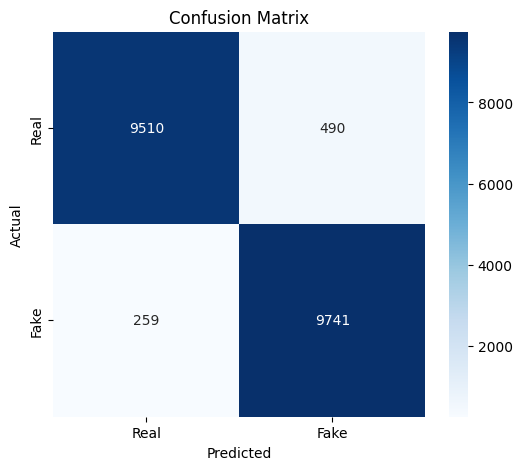

In [16]:
# =========================
# CONFUSION MATRIX
# =========================

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Real', 'Fake'],
    yticklabels=['Real', 'Fake']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

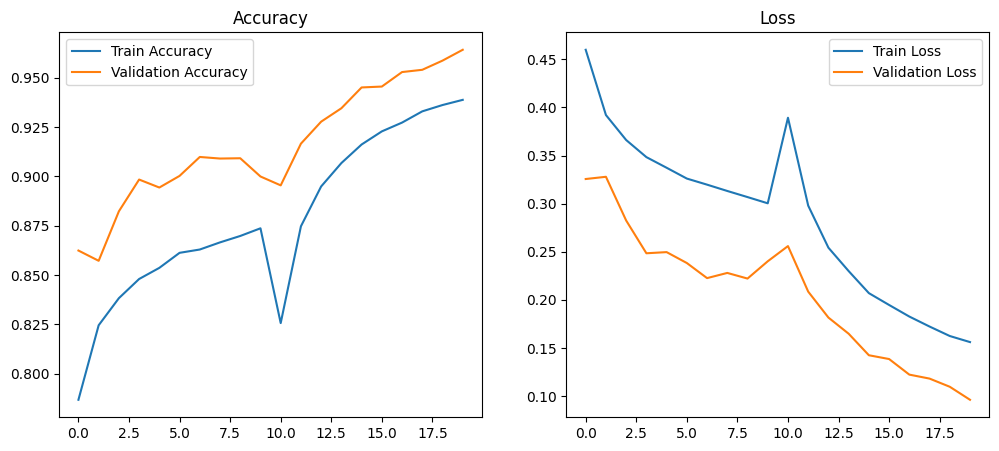

In [17]:
# =========================
# TRAINING CURVES
# =========================

acc = history_initial.history['accuracy'] + history_finetune.history['accuracy']
val_acc = history_initial.history['val_accuracy'] + history_finetune.history['val_accuracy']

loss = history_initial.history['loss'] + history_finetune.history['loss']
val_loss = history_initial.history['val_loss'] + history_finetune.history['val_loss']

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Validation Loss')
plt.title('Loss')
plt.legend()

plt.show()

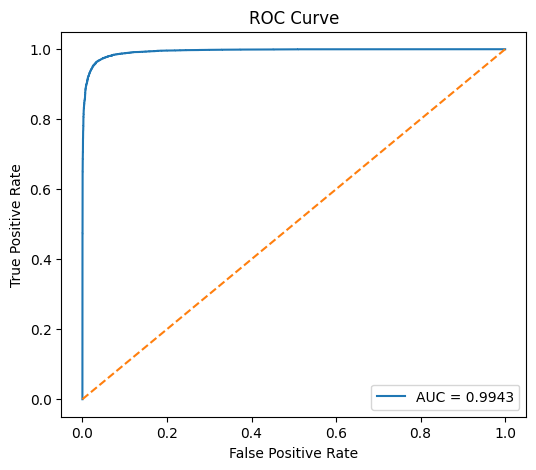

In [18]:
# =========================
# ROC Curve
# =========================
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_true, pred_probs)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()